# 02 - Exploratory Data Analysis

## Objective
Explore appliance energy consumption patterns, feature distributions,
time-based trends, and relationships between features and the target
variable before preprocessing and model development.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load dataset
DATA_PATH = "../data/energydata_complete.csv"
df = pd.read_csv(DATA_PATH)

# Convert timestamp to datetime
df["date"] = pd.to_datetime(df["date"])

# Create directory for saving plots
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Basic verification
print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Target column: Appliances")

df.head()

Dataset shape: (19735, 29)
Date range: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Target column: Appliances


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


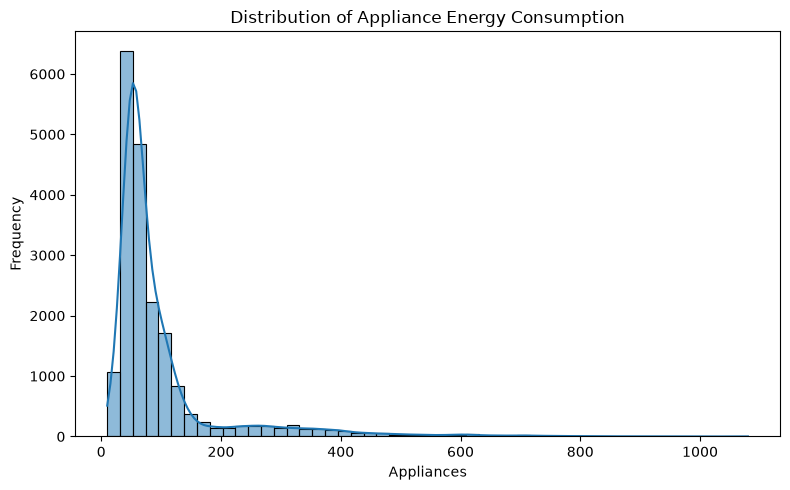

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Appliances",
    bins=50,
    kde=True
)

plt.title("Distribution of Appliance Energy Consumption")
plt.xlabel("Appliances")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "appliances_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [4]:
target = df["Appliances"]

print("Mean:", target.mean())
print("Median:", target.median())
print("Standard deviation:", target.std())
print("Skewness:", target.skew())

print("\nPercentiles:")
print(target.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

Mean: 97.6949581960983
Median: 60.0
Standard deviation: 102.52489053740624
Skewness: 3.386367214743062

Percentiles:
0.25     50.0
0.50     60.0
0.75    100.0
0.90    196.0
0.95    330.0
0.99    576.6
Name: Appliances, dtype: float64


### Target Distribution: Appliances

- The target distribution is strongly right-skewed (skewness ≈ 3.39).
- The mean (97.69) is substantially higher than the median (60).
- The 75th percentile is 100, while the 95th percentile is 330.
- A small proportion of observations have substantially higher consumption values.
- These high values require investigation; they should not automatically be treated as errors or removed.

Conclusion: Appliance consumption is not normally distributed and is concentrated toward lower values.

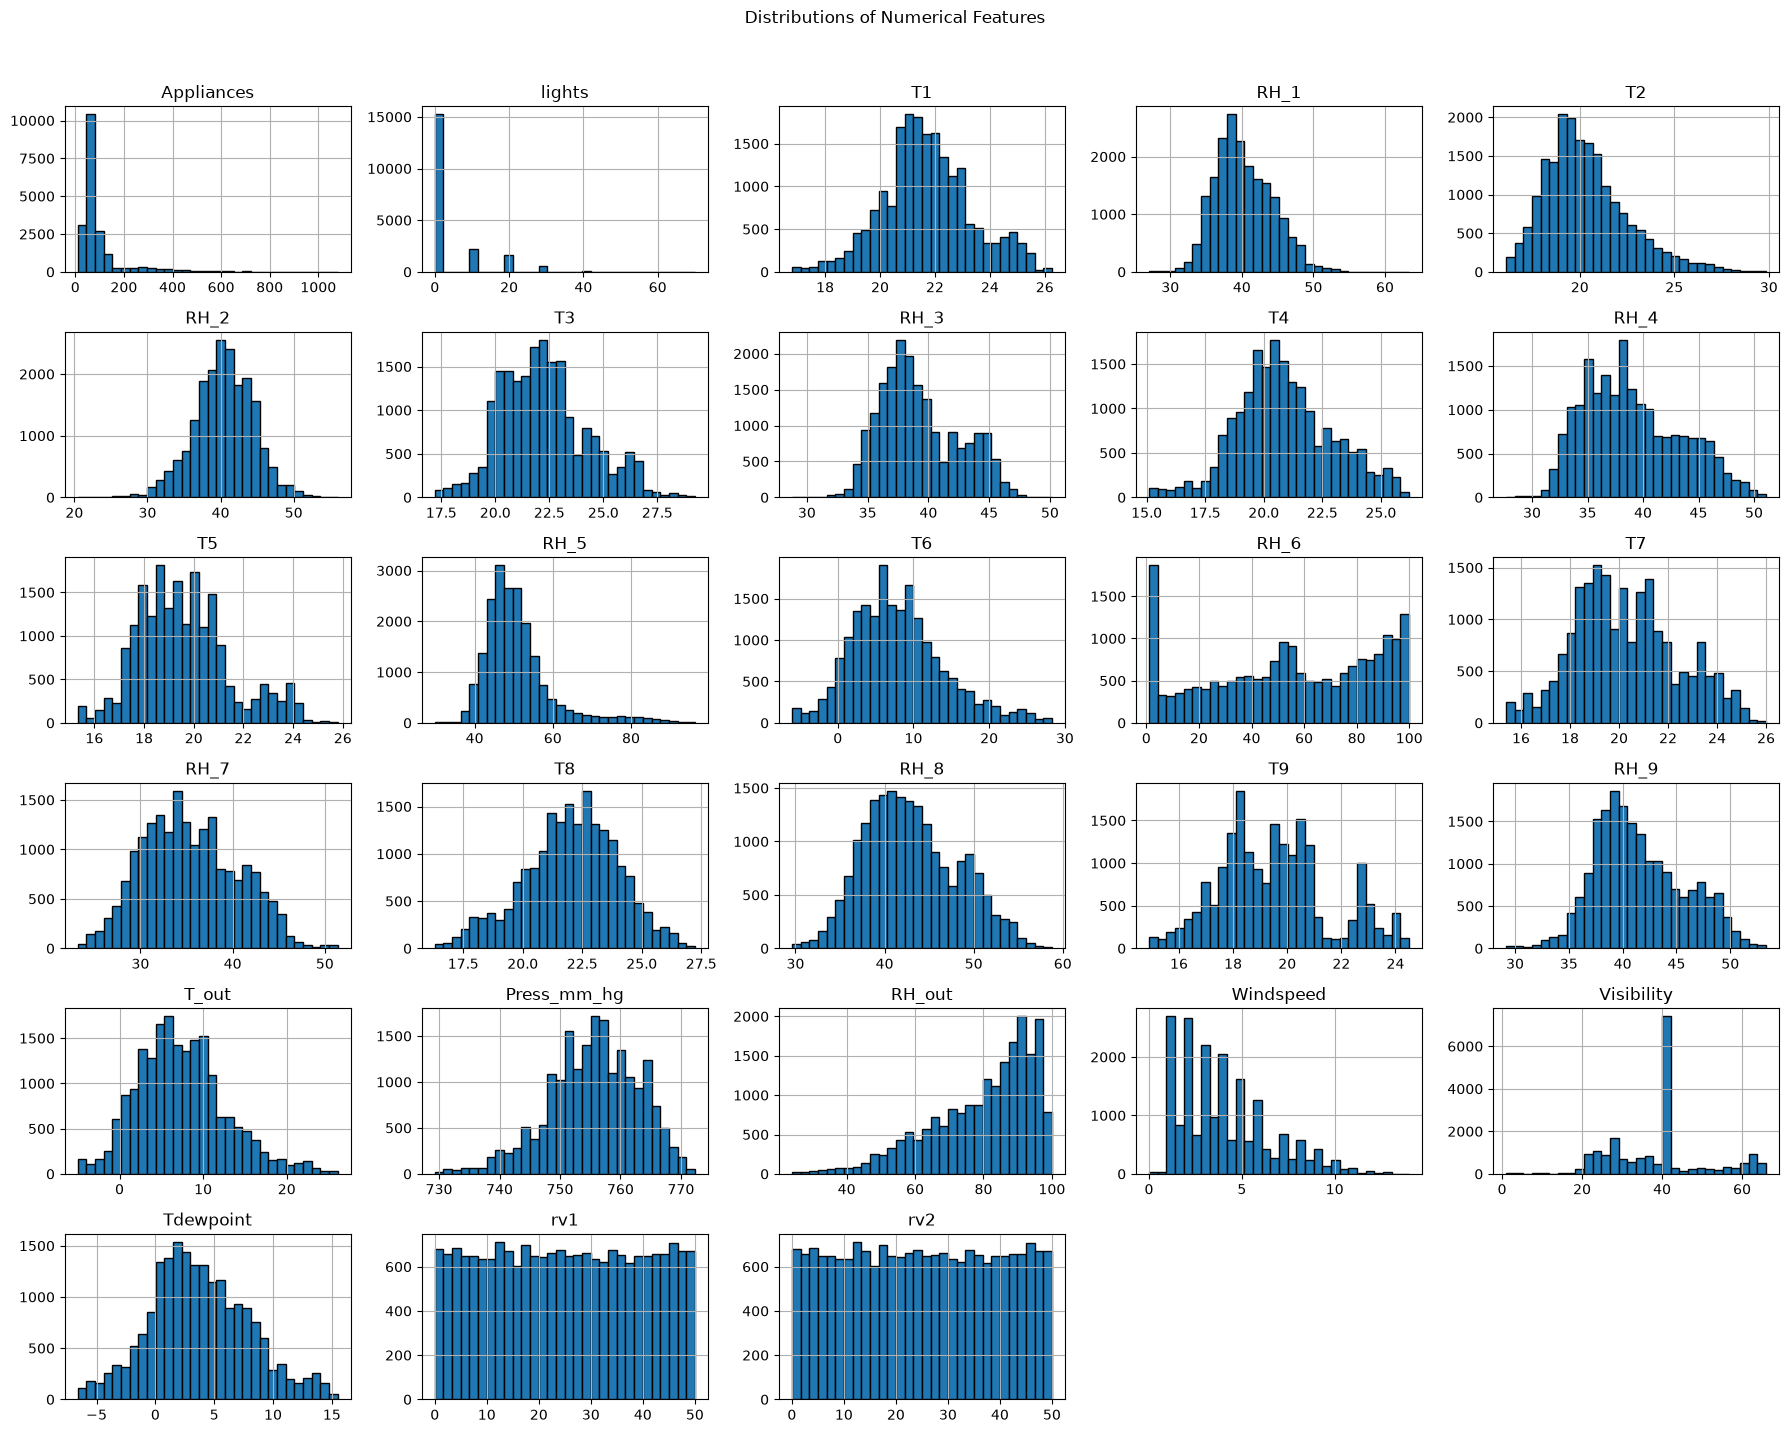

In [5]:
numeric_features = df.select_dtypes(include="number").columns

df[numeric_features].hist(
    bins=30,
    figsize=(18, 14),
    layout=(6, 5),
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "numerical_feature_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Numerical Feature Distributions

- Appliances is strongly right-skewed, with occasional high values.
- Lights contains many low or zero values and is discrete.
- Temperature and humidity features show varying distribution shapes,
  including asymmetry and multiple peaks.
- Windspeed is right-skewed.
- RH_out has substantial concentration near the upper end of its range.
- Visibility shows a pronounced spike near 40 that warrants investigation.
- rv1 and rv2 have similar-looking distributions and were found to be
  identical in Notebook 01.

These plots describe feature distributions but do not establish
relationships with the target or imply causation.

In [6]:
visibility_counts = df["Visibility"].value_counts()

print("Most frequent Visibility values:")
print(visibility_counts.head(10))

print("\nPercentage of rows with Visibility = 40:")
print(f"{(df['Visibility'].eq(40).mean() * 100):.2f}%")

Most frequent Visibility values:
Visibility
40.000000    7224
29.000000     449
36.333333     257
23.000000     247
28.000000     245
32.666667     241
34.500000     240
30.833333     237
38.166667     236
62.000000     236
Name: count, dtype: int64

Percentage of rows with Visibility = 40:
36.61%


In [7]:
visibility_comparison = (
    df.assign(visibility_is_40=df["Visibility"].eq(40))
    .groupby("visibility_is_40")["Appliances"]
    .agg(["count", "mean", "median", "std"])
)

visibility_comparison.index = [
    "Visibility != 40",
    "Visibility == 40"
]

visibility_comparison

,count,mean,median,std
Visibility != 40,12511,91.954280,60.0,97.584462
Visibility == 40,7224,107.637043,70.0,109.859616


- Visibility equals 40 in 7,224 observations (36.61%).
- Rows with Visibility = 40 have a mean Appliances value of 107.64,
  compared with 91.95 for other rows.
- Their median values are 70 and 60, respectively.
- This is a descriptive association; causation has not been established.
- The unusual concentration at 40 warrants further investigation.

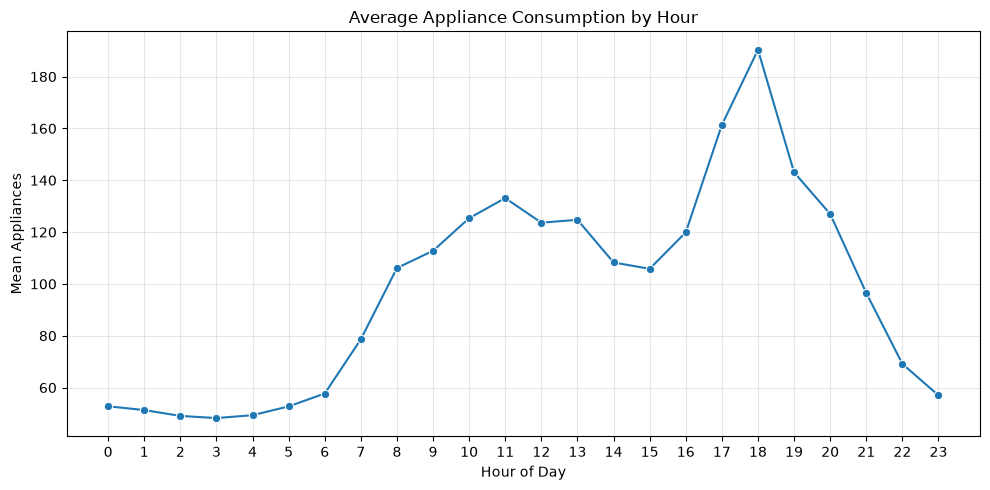

In [8]:
df["hour"] = df["date"].dt.hour

hourly_consumption = (
    df.groupby("hour")["Appliances"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=hourly_consumption.index,
    y=hourly_consumption.values,
    marker="o"
)

plt.title("Average Appliance Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Appliances")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hourly_appliance_consumption.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Hourly Appliance Consumption

- Average consumption is lowest during the early morning hours.
- Consumption increases substantially from around 07:00 to 11:00.
- A second, sharper rise occurs during the late afternoon.
- The highest hourly mean occurs at 18:00, at approximately 190.
- Consumption declines through the evening after the peak.

These results suggest a pronounced daily pattern in appliance consumption.
The reasons for the pattern have not been established.

In [9]:
df["day_type"] = np.where(
    df["date"].dt.dayofweek < 5,
    "Weekday",
    "Weekend"
)

day_type_summary = (
    df.groupby("day_type")["Appliances"]
    .agg(["count", "mean", "median", "std"])
)

day_type_summary

C:\Users\SUBHAM\AppData\Local\Temp\ipykernel_21344\3987856629.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["date"].dt.dayofweek < 5,


,count,mean,median,std
day_type,,,,
Weekday,14263,96.587674,60.0,103.086372
Weekend,5472,100.581140,70.0,100.998987


### Weekday vs Weekend Consumption

- Weekday mean Appliances: 96.59.
- Weekend mean Appliances: 100.58.
- Weekend median: 70; weekday median: 60.
- The two groups have similar standard deviations.
- Weekend consumption is slightly higher on average in this dataset.

This is a descriptive association and does not establish causation.

In [10]:
numeric_df = df.select_dtypes(include="number")

correlations = (
    numeric_df.corr()["Appliances"]
    .drop("Appliances")
    .sort_values(ascending=False)
)

print("Features most positively correlated with Appliances:")
print(correlations.head(10))

print("\nFeatures most negatively correlated with Appliances:")
print(correlations.tail(10).sort_values())

Features most positively correlated with Appliances:
hour         0.216792
lights       0.197278
T2           0.120073
T6           0.117638
T_out        0.099155
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
T1           0.055447
T4           0.040281
Name: Appliances, dtype: float64

Features most negatively correlated with Appliances:
RH_out        -0.152282
RH_8          -0.094039
RH_6          -0.083178
RH_2          -0.060465
RH_7          -0.055642
RH_9          -0.051462
Press_mm_hg   -0.034885
rv1           -0.011145
rv2           -0.011145
Visibility     0.000230
Name: Appliances, dtype: float64


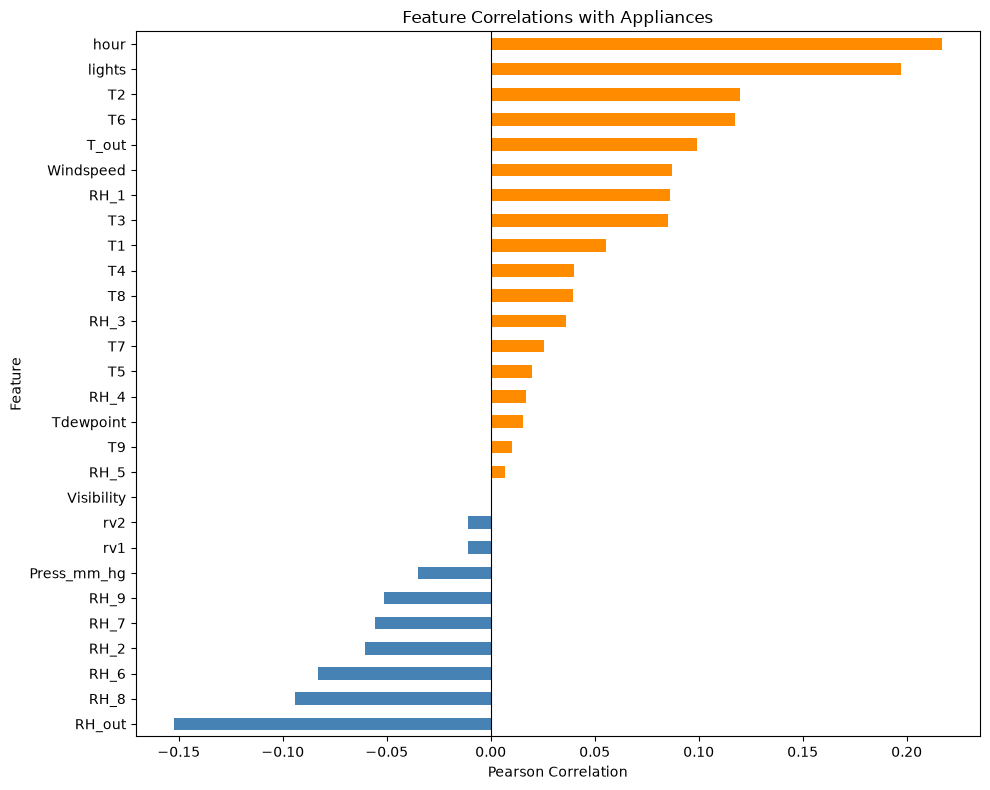

In [11]:
plt.figure(figsize=(10, 8))

correlations.sort_values().plot(
    kind="barh",
    color=[
        "steelblue" if value < 0 else "darkorange"
        for value in correlations.sort_values()
    ]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature Correlations with Appliances")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_correlations.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

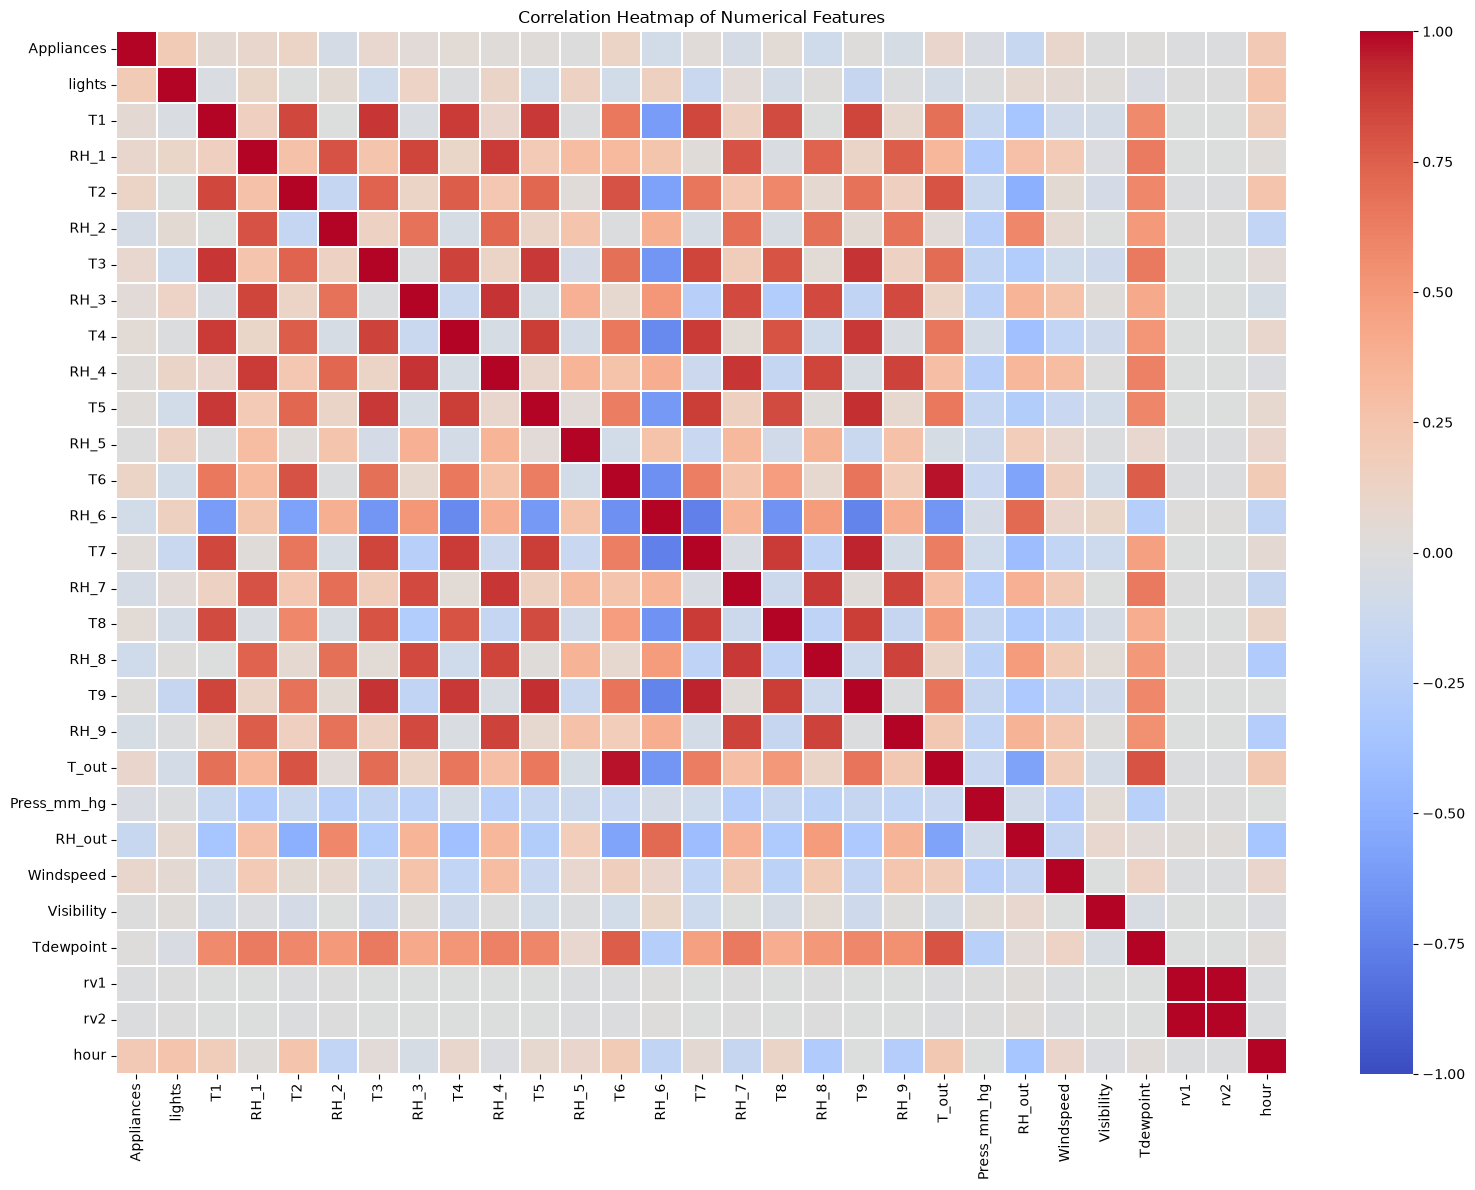

In [12]:
# Exclude helper columns created specifically for EDA
exclude_cols = ["day_type"]

heatmap_df = df.drop(
    columns=exclude_cols,
    errors="ignore"
).select_dtypes(include="number")

corr_matrix = heatmap_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Correlation Heatmap Findings

- Several temperature sensors are strongly positively correlated.
- Several humidity sensors also show strong positive correlations.
- RH_6 has strong negative correlations with multiple temperature sensors.
- T6 and T_out appear perfectly correlated; this needs numerical verification.
- rv1 and rv2 are identical and therefore redundant.
- Correlation between predictors may affect some models, but the impact
  depends on the model being used.

Correlation indicates linear association, not causation.

In [13]:
# Get unique feature pairs, excluding self-correlations
corr_pairs = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(ascending=False)
)

print("Strongest positive feature pairs:")
print(corr_pairs.head(10))

print("\nStrongest negative feature pairs:")
print(corr_pairs.tail(10).sort_values())

Strongest positive feature pairs:
rv1   rv2      1.000000
T6    T_out    0.974787
T7    T9       0.944776
T5    T9       0.911055
T3    T9       0.901324
RH_3  RH_4     0.898978
RH_4  RH_7     0.894301
T1    T3       0.892402
T4    T9       0.889439
T3    T5       0.888169
dtype: float64

Strongest negative feature pairs:
hour  RH_9          NaN
      T_out         NaN
      Press_mm_hg   NaN
      RH_out        NaN
      Windspeed     NaN
      Visibility    NaN
      Tdewpoint     NaN
      rv1           NaN
      rv2           NaN
      hour          NaN
dtype: float64


In [14]:
corr_pairs = (
    corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape, dtype=bool),
            k=1
        )
    )
    .stack()
    .sort_values()
)

print("Strongest negative feature pairs:")
print(corr_pairs.head(10))

print("\nStrongest positive feature pairs:")
print(corr_pairs.tail(10).sort_values(ascending=False))

Strongest negative feature pairs:
RH_6  T7      -0.753973
      T9      -0.738940
T4    RH_6    -0.703149
T6    RH_6    -0.672137
RH_6  T8      -0.665869
T3    RH_6    -0.647672
RH_6  T_out   -0.641572
T5    RH_6    -0.632384
T1    RH_6    -0.615045
T2    RH_6    -0.580372
dtype: float64

Strongest positive feature pairs:
hour  RH_9          NaN
      T_out         NaN
      Press_mm_hg   NaN
      RH_out        NaN
      Windspeed     NaN
      Visibility    NaN
      Tdewpoint     NaN
      rv1           NaN
      rv2           NaN
      hour          NaN
dtype: float64


In [17]:
corr_pairs = (
    corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape, dtype=bool),
            k=1
        )
    )
    .stack()
    .dropna()
    .sort_values()
)

print("Strongest negative feature pairs:")
print(corr_pairs.head(10))

print("\nStrongest positive feature pairs:")
print(corr_pairs.tail(10).sort_values(ascending=False))

Strongest negative feature pairs:
RH_6  T7      -0.753973
      T9      -0.738940
T4    RH_6    -0.703149
T6    RH_6    -0.672137
RH_6  T8      -0.665869
T3    RH_6    -0.647672
RH_6  T_out   -0.641572
T5    RH_6    -0.632384
T1    RH_6    -0.615045
T2    RH_6    -0.580372
dtype: float64

Strongest positive feature pairs:
rv1   rv2      1.000000
T6    T_out    0.974787
T7    T9       0.944776
T5    T9       0.911055
T3    T9       0.901324
RH_3  RH_4     0.898978
RH_4  RH_7     0.894301
T1    T3       0.892402
T4    T9       0.889439
T3    T5       0.888169
dtype: float64


### Strongest Feature-to-Feature Correlations

- rv1 and rv2 have a perfect correlation of 1.000 and are identical.
- T6 and T_out have a strong positive correlation of approximately 0.975.
- T7 and T9 have a strong positive correlation of approximately 0.945.
- RH_6 and T7 have a strong negative correlation of approximately -0.754.
- RH_6 and T9 have a strong negative correlation of approximately -0.739.

These relationships indicate potential redundancy and shared patterns
among sensor features. Correlation alone does not establish causation
or determine which features should be removed.

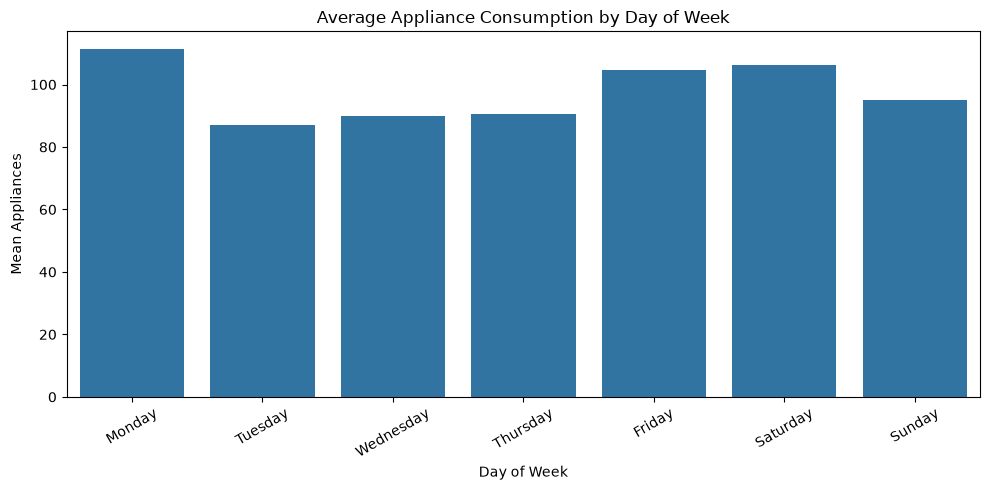

day_name
Monday       111.450684
Tuesday       87.125000
Wednesday     89.930556
Thursday      90.434028
Friday       104.622144
Saturday     106.246345
Sunday        94.915936
Name: Appliances, dtype: float64

In [18]:
df["day_name"] = df["date"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_consumption = (
    df.groupby("day_name")["Appliances"]
    .mean()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=daily_consumption.index,
    y=daily_consumption.values
)

plt.title("Average Appliance Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Mean Appliances")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "daily_appliance_consumption.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

daily_consumption

In [21]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nFIGURES_DIR currently points to:")
print(FIGURES_DIR)

print("\nDoes that directory exist?")
print(Path(FIGURES_DIR).exists())

print("\nWhere is the project folder?")
print(Path.cwd().resolve())

Notebook working directory:
c:\Users\SUBHAM\Desktop\Codes\PROJECTS\Appliance-Energy-Intelligence\notebooks

FIGURES_DIR currently points to:
..\reports\figures

Does that directory exist?
True

Where is the project folder?
C:\Users\SUBHAM\Desktop\Codes\PROJECTS\Appliance-Energy-Intelligence\notebooks


In [22]:
from pathlib import Path

figures_dir = Path(FIGURES_DIR).resolve()

print("Resolved figure directory:", figures_dir)
print("\nFiles currently inside:")

for path in figures_dir.iterdir():
    if path.is_file():
        print(path.name)

Resolved figure directory: C:\Users\SUBHAM\Desktop\Codes\PROJECTS\Appliance-Energy-Intelligence\reports\figures

Files currently inside:
appliances_distribution.png
correlation_heatmap.png
daily_appliance_consumption.png
feature_correlations.png
hourly_appliance_consumption.png
numerical_feature_distributions.png


In [23]:
print("Dataset shape:", df.shape)
print("Target column exists:", "Appliances" in df.columns)
print("Missing values:", df.isnull().sum().sum())

print("\nSaved figures:")
for filename in [
    "hourly_appliance_consumption.png",
    "feature_correlations.png",
    "correlation_heatmap.png",
    "daily_appliance_consumption.png",
]:
    print(filename, ":", (FIGURES_DIR / filename).exists())

Dataset shape: (19735, 32)
Target column exists: True
Missing values: 0

Saved figures:
hourly_appliance_consumption.png : True
feature_correlations.png : True
correlation_heatmap.png : True
daily_appliance_consumption.png : True


## Exploratory Data Analysis — Key Findings

### 1. Target distribution
- `Appliances` is strongly right-skewed, with skewness approximately 3.39.
- Mean consumption is 97.69, while the median is 60.
- The 99th percentile is 576.6, indicating occasional high-consumption observations.

### 2. Numerical feature distributions
- Temperature and humidity sensors show varied distributions.
- `Windspeed` is right-skewed.
- `Visibility` has a pronounced spike at 40, occurring in 36.61% of observations.
- `rv1` and `rv2` are identical columns.

### 3. Time-based patterns
- Average consumption is lowest during the early morning.
- The hourly average peaks around 18:00 at approximately 190.
- Weekend mean consumption (100.58) is slightly higher than weekday mean consumption (96.59).
- Monday has the highest daily average (111.45), while Tuesday has the lowest (87.13).

### 4. Relationships with the target
- `hour` has the strongest positive Pearson correlation with `Appliances` (approximately 0.217).
- `lights` is the second strongest positive correlate (approximately 0.197).
- `RH_out` has the strongest negative correlation (approximately -0.152).
- These correlations are relatively weak and do not establish causation.

### 5. Relationships between features
- `T6` and `T_out` have a strong positive correlation (approximately 0.975).
- `T7` and `T9` have a strong positive correlation (approximately 0.945).
- `RH_6` and `T7` have a strong negative correlation (approximately -0.754).
- `rv1` and `rv2` have a perfect correlation of 1.0.

### 6. Limitations
- Observed associations do not establish causal relationships.
- Correlation measures linear relationships and may miss nonlinear patterns.
- Day-of-week and hourly averages can hide variation across individual dates.
- The unusual concentration of `Visibility = 40` requires further investigation.

### Conclusion
The dataset shows clear temporal patterns and substantial relationships among some sensor features. These findings will guide preprocessing and subsequent model experiments without assuming that any individual feature necessarily causes changes in appliance consumption.